# NiftyQuant: predicting 5-day forward returns of liquid NSE stocks

A reproducible research notebook that asks one narrow question: **do simple, leakage-free technical
features computed at the close of day *t* predict the next 5-trading-day return of liquid NSE-listed
stocks better than naive baselines?**

The data is the public Kaggle dataset `sagara9595/stock-data` (daily Yahoo-Finance-style OHLCV files
for NSE and BSE listings, 2000-2020). It is **not** an index dataset; no index-membership claim is made.

Every number quoted in the README is produced by a cell in this notebook. The notebook runs top to
bottom in a fresh kernel.

> **Disclaimer.** These are experiments on historical market data. They are not financial advice, they do
> not guarantee future returns, and no profit claim is made.

## 1. Configuration

All tunable choices, seeds and paths live in this one cell. `SEED` is passed explicitly to every
estimator, random sampler and permutation routine below.

In [1]:
import time
from pathlib import Path

RUN_START = time.time()

# --- reproducibility --------------------------------------------------------
SEED = 42
N_JOBS = -1            # parallelism for RandomForest / permutation importance

# --- data provenance ----------------------------------------------------------
KAGGLE_DATASET = "sagara9595/stock-data"
DATASET_URL = "https://www.kaggle.com/datasets/sagara9595/stock-data"
DATASET_VERSION = 1
DATASET_LICENSE = "CC0-1.0 (Kaggle dataset metadata 'licenses' field, retrieved 2026-10-08)"
EXCHANGE_SUFFIX = ".NS"     # NSE only: avoids near-duplicate NSE/BSE series of cross-listed firms
PRICE_COL = "Close"         # split/bonus-adjusted close; see Section 4 for why not 'Adj Close'

# --- universe (chosen ex ante, from a formation window that precedes all modelling data) ---
FORMATION_START, FORMATION_END = "2004-01-01", "2005-12-31"
MIN_FORMATION_COVERAGE = 0.95   # traded (volume > 0) on >= 95% of formation-window trading days
UNIVERSE_SIZE = 150             # top-N by median daily traded value (Close x Volume) in formation window
CALENDAR_MIN_COVERAGE = 0.50    # a date enters the trading calendar if >= 50% of the universe traded

# --- cleaning -----------------------------------------------------------------
JUMP_LOG_THRESHOLD = 0.405      # |log(C_t/C_{t-1})| > ln(1.5): one-day move > +50% or < -33%
MAX_FFILL = 5                   # max trading days a last close is carried when a stock did not trade

# --- target / horizon ---------------------------------------------------------
HORIZON = 5                     # h trading days (one trading week); justified in Section 6

# --- chronological splits (by date) ---------------------------------------------
SAMPLE_START = "2006-01-01"     # first prediction date (2004-2005 used for universe + feature warm-up)
VAL_START = "2015-01-01"
TEST_START = "2018-01-01"       # test = 2018-01-01 .. end of data (2020-06-05); untouched until Section 12
WF_TEST_YEARS = [2012, 2013, 2014, 2015, 2016, 2017]   # expanding-window walk-forward folds (dev period only)
TARGET_CLIP_Q = (0.005, 0.995)  # training labels winsorised at train-fold quantiles (fit-time only)

# --- model selection rule (fixed before looking at any results) ----------------
MIN_POSITIVE_IC_FOLDS = 2 / 3   # mean per-date IC must be > 0 in at least 2/3 of walk-forward folds
MAX_RMSE_RATIO = 1.01           # walk-forward RMSE no more than 1% above the best baseline's RMSE

# --- backtest -----------------------------------------------------------------
COST_BPS = 10                   # transaction cost per side, in basis points of traded notional
QUANTILE = 0.20                 # long top 20% (and, for the long-short variant, short bottom 20%)

# --- compute ------------------------------------------------------------------
USE_GPU = False   # all estimators used are scikit-learn (CPU-only); GPU is detected and logged, not used

ARTIFACTS = Path("artifacts")
ARTIFACTS.mkdir(exist_ok=True)
print(f"SEED={SEED}  HORIZON={HORIZON}  universe=top {UNIVERSE_SIZE} {EXCHANGE_SUFFIX}  artifacts -> ./{ARTIFACTS.as_posix()}/")

SEED=42  HORIZON=5  universe=top 150 .NS  artifacts -> ./artifacts/


## 2. Imports

Only what is used. Runtime environment (platform, CPU, GPU presence, package versions) is recorded here.

In [2]:
import hashlib
import os
import platform
import subprocess
import sys
from datetime import datetime

import kagglehub
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from scipy.stats import pearsonr, spearmanr
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import ElasticNet, LinearRegression, Ridge
from sklearn.metrics import make_scorer, mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.precision", 5)
plt.rcParams.update({"figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})


def detect_gpu():
    """Return the NVIDIA GPU name if nvidia-smi is available, else None (logged only)."""
    try:
        out = subprocess.run(["nvidia-smi", "--query-gpu=name", "--format=csv,noheader"],
                             capture_output=True, text=True, timeout=15)
        if out.returncode != 0:
            return None
        return out.stdout.strip() or None
    except (OSError, subprocess.SubprocessError):
        return None


def cpu_name():
    """Human-readable CPU name (Windows registry when available, else platform.processor())."""
    if sys.platform == "win32":
        try:
            import winreg
            key = winreg.OpenKey(winreg.HKEY_LOCAL_MACHINE, r"HARDWARE\DESCRIPTION\System\CentralProcessor\0")
            return winreg.QueryValueEx(key, "ProcessorNameString")[0].strip()
        except OSError:
            pass
    return platform.processor() or "unknown"


GPU_NAME = detect_gpu()
ENV = {
    "python": sys.version.split()[0],
    "platform": platform.platform(),
    "processor": cpu_name(),
    "logical_cpus": os.cpu_count(),
    "gpu_detected": GPU_NAME,
    "gpu_used": USE_GPU,
    "numpy": np.__version__, "pandas": pd.__version__, "scikit-learn": sklearn.__version__,
    "scipy": scipy.__version__, "matplotlib": matplotlib.__version__,
    "kagglehub": getattr(kagglehub, "__version__", "unknown"),
}
pd.Series(ENV, name="value").to_frame()

,value
python,3.11.9
platform,Windows-10-10.0.26300-SP0
processor,Intel(R) Core(TM) Ultra 9 275HX
logical_cpus,24
gpu_detected,NVIDIA GeForce RTX 5070 Laptop GPU
gpu_used,False
numpy,2.4.6
pandas,3.0.6
scikit-learn,1.9.1
scipy,1.17.1


## 3. Data acquisition

`kagglehub` downloads (or re-uses) the dataset in its user cache, **outside the repository**. Nothing
from the data directory is copied into the repo. SHA-256 checksums of every NSE file read are written to
`artifacts/data_checksums_nse.csv`, plus one combined digest.

In [3]:
DATA_ROOT = Path(kagglehub.dataset_download(KAGGLE_DATASET)).resolve()
DATA_DIR = DATA_ROOT / "Data"
REPO_DIR = Path.cwd().resolve()
assert REPO_DIR not in DATA_ROOT.parents and DATA_ROOT != REPO_DIR, "data must be cached outside the repo"

all_files = sorted(p.name for p in DATA_DIR.glob("*.csv"))
ns_files = [f for f in all_files if f.endswith(".NS.csv")]
bo_files = [f for f in all_files if f.endswith(".BO.csv")]
other_files = sorted(set(all_files) - set(ns_files) - set(bo_files))
download_date = datetime.fromtimestamp(DATA_ROOT.stat().st_mtime).date().isoformat()


def sha256_file(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as fh:
        for block in iter(lambda: fh.read(chunk), b""):
            h.update(block)
    return h.hexdigest()


checksums = pd.DataFrame(
    [(f, (DATA_DIR / f).stat().st_size, sha256_file(DATA_DIR / f)) for f in ns_files],
    columns=["file", "bytes", "sha256"])
COMBINED_SHA256 = hashlib.sha256("\n".join(checksums.file + ":" + checksums.sha256).encode()).hexdigest()
checksums.to_csv(ARTIFACTS / "data_checksums_nse.csv", index=False)

total_bytes = sum((DATA_DIR / f).stat().st_size for f in all_files)
print(f"cache location        : <kagglehub cache>/{DATA_ROOT.relative_to(DATA_ROOT.parents[4]).as_posix()}")
print(f"dataset version       : {DATASET_VERSION}   (cache timestamp / download date: {download_date})")
print(f"files                 : {len(all_files)} total = {len(ns_files)} *.NS.csv + {len(bo_files)} *.BO.csv + {len(other_files)} other")
print(f"total size            : {total_bytes / 1e9:.2f} GB")
print(f"NSE files hashed      : {len(checksums)}  ({checksums.bytes.sum() / 1e6:.1f} MB)")
print(f"combined SHA-256 (NSE): {COMBINED_SHA256}")

cache location        : <kagglehub cache>/datasets/sagara9595/stock-data/versions/1
dataset version       : 1   (cache timestamp / download date: 2026-10-08)
files                 : 5028 total = 1549 *.NS.csv + 3479 *.BO.csv + 0 other
total size            : 1.44 GB
NSE files hashed      : 1549  (443.1 MB)
combined SHA-256 (NSE): dd1816320ee495acf36e5823f1bdf3861c806362d31c10b733a9d01d8afa140b


## 4. Dataset inspection

What the files actually contain, measured rather than assumed. All 1,549 NSE files are loaded; the BSE
files are only scanned (dates and row counts) to describe the dataset and the cross-listing overlap.

In [4]:
OHLCV = ["Open", "High", "Low", "Close", "Adj Close", "Volume"]
raw = pd.concat([pd.read_csv(DATA_DIR / f).assign(ticker=f[:-4]) for f in ns_files], ignore_index=True)
raw["Date"] = pd.to_datetime(raw["Date"], format="%Y-%m-%d")
print("columns:", list(raw.columns[:-1]), "| rows:", len(raw), "| tickers:", raw.ticker.nunique())

bo_scan = []
for f in bo_files:
    d = pd.read_csv(DATA_DIR / f, usecols=["Date"])
    bo_scan.append((f[:-7], len(d), d.Date.min(), d.Date.max()))
bo_scan = pd.DataFrame(bo_scan, columns=["base", "rows", "start", "end"])

ok = raw.dropna(subset=OHLCV)
ratio = ok["Adj Close"] / ok["Close"]
ns_base = {t[:-3] for t in raw.ticker.unique()}
bo_base = set(bo_scan.base)
per_ticker = raw.groupby("ticker").Date.agg(["size", "min", "max"])

summary = pd.Series({
    "files total": len(all_files),
    "NSE files (*.NS.csv)": len(ns_files),
    "BSE files (*.BO.csv)": len(bo_files),
    "BSE files with numeric scrip codes": int(bo_scan.base.str.isdigit().sum()),
    "NSE base symbols also present as .BO": len(ns_base & bo_base),
    "NSE rows": len(raw),
    "NSE date range": f"{raw.Date.min().date()} .. {raw.Date.max().date()}",
    "BSE date range": f"{bo_scan.start.min()} .. {bo_scan.end.max()}",
    "BSE rows": int(bo_scan.rows.sum()),
    "NSE distinct dates": raw.Date.nunique(),
    "NSE rows on Saturdays/Sundays": int((raw.Date.dt.dayofweek >= 5).sum()),
    "NSE rows per ticker (min / median / max)": f"{per_ticker['size'].min()} / {int(per_ticker['size'].median())} / {per_ticker['size'].max()}",
    "NSE tickers with last date >= 2020-06-01": int((per_ticker['max'] >= "2020-06-01").sum()),
    "NSE all-NaN rows": int(raw[OHLCV].isna().all(axis=1).sum()),
    "NSE rows with any NaN": int(raw[OHLCV].isna().any(axis=1).sum()),
    "NSE duplicate (ticker, Date) rows": int(raw.duplicated(["ticker", "Date"]).sum()),
    "NSE zero-volume rows (share)": f"{(ok.Volume == 0).mean():.4f}",
    "NSE non-positive Open/High/Low/Close": int((ok[["Open", "High", "Low", "Close"]] <= 0).sum().sum()),
    "NSE non-positive Adj Close rows": int((ok["Adj Close"] <= 0).sum()),
    "NSE tickers with non-positive Adj Close": int(ok.loc[ok["Adj Close"] <= 0, "ticker"].nunique()),
    "NSE rows with Adj Close / Close > 1.001": int((ratio > 1.001).sum()),
    "NSE rows with Close outside [Low, High]": int(((ok.Close > ok.High * 1.0001) | (ok.Close < ok.Low * 0.9999)).sum()),
})
summary.to_frame("value").to_csv(ARTIFACTS / "dataset_summary.csv")
summary.to_frame("value")

columns: ['Date', 'Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume'] | rows: 4741184 | tickers: 1549


,value
files total,5028
NSE files (*.NS.csv),1549
BSE files (*.BO.csv),3479
BSE files with numeric scrip codes,10
NSE base symbols also present as .BO,1255
NSE rows,4741184
NSE date range,2000-01-03 .. 2020-06-05
BSE date range,2000-01-03 .. 2020-06-05
BSE rows,10833334
NSE distinct dates,5221


**Which price column?** Yahoo-style files carry `Close` (adjusted for splits and bonus issues) and
`Adj Close` (additionally back-adjusted for dividends). The checks below test both claims on known
corporate actions and look for impossible adjustment factors.

In [5]:
# (a) Is Close split/bonus-adjusted?  TCS issued 1:1 bonus shares (ex-dates 2009-06-16, 2018-05-31);
#     INFY issued 1:1 bonuses (ex-dates 2015-06-12, 2018-09-04). Unadjusted data would show ~ -50% days.
ok = ok.sort_values(["ticker", "Date"])
ok["close_ret"] = ok.groupby("ticker").Close.pct_change()
ok["adj_ratio"] = ok["Adj Close"] / ok["Close"]
events = [("TCS.NS", "2009-06-16"), ("TCS.NS", "2018-05-31"), ("INFY.NS", "2015-06-12"), ("INFY.NS", "2018-09-04")]
ev = pd.concat([ok[(ok.ticker == t) & (ok.Date == d)] for t, d in events])
print("Close return on bonus ex-dates (would be ~ -0.50 if unadjusted):")
print(ev[["ticker", "Date", "Close", "close_ret", "adj_ratio"]].to_string(index=False))

# (b) Adj Close / Close factor: should lie in (0, 1] and only step up at ex-dividend dates.
print(f"\nAdj Close / Close ratio: min {ok.adj_ratio.min():.3f}, max {ok.adj_ratio.max():.3f}; "
      f"rows with ratio <= 0: {(ok.adj_ratio <= 0).sum()}, rows with ratio > 1.001: {(ok.adj_ratio > 1.001).sum()}")

# (c) Implied dividend yield from the factor steps (only for well-behaved factors 0 < ratio <= 1), 2006-2019.
clean_r = ok[(ok.adj_ratio > 0) & (ok.adj_ratio <= 1.0001)].copy()
clean_r["step"] = 1 - clean_r.groupby("ticker").adj_ratio.shift(1) / clean_r.adj_ratio
yr = clean_r[(clean_r.Date >= "2006-01-01") & (clean_r.Date < "2020-01-01") & (clean_r.step.between(0, 0.5))]
yearly = yr.groupby(["ticker", yr.Date.dt.year]).step.sum()
print(f"implied dividend yield per ticker-year (median across ticker-years 2006-2019): {yearly.median():.4f}")

# (d) The largest one-day Close moves: unadjusted corporate actions / bad ticks, not real returns.
print("\nfive largest |one-day Close return| rows in the NSE files:")
print(ok.loc[ok.close_ret.abs().nlargest(5).index, ["ticker", "Date", "Close", "Volume", "close_ret"]].to_string(index=False))
print("\nABB.NS early history: Adj Close / Close factor by year-end (illustrates a broken factor):")
print(ok[ok.ticker == "ABB.NS"].set_index("Date").adj_ratio.resample("YE").last().loc[:"2006"].round(3).to_string())

Close return on bonus ex-dates (would be ~ -0.50 if unadjusted):
 ticker       Date      Close  close_ret  adj_ratio
 TCS.NS 2009-06-16  194.57500    0.00039    0.73374
 TCS.NS 2018-05-31 1741.05005   -0.00911    0.95230
INFY.NS 2015-06-12  493.76300   -0.01131    0.80840
INFY.NS 2018-09-04  737.15002    0.02792    0.93534

Adj Close / Close ratio: min -68.803, max 190.208; rows with ratio <= 0: 10388, rows with ratio > 1.001: 1697


implied dividend yield per ticker-year (median across ticker-years 2006-2019): 0.0066

five largest |one-day Close return| rows in the NSE files:


       ticker       Date     Close   Volume  close_ret
  GOLDBEES.NS 2019-12-23  33.65000 909544.0   99.00001
  HINDZINC.NS 2006-11-21  87.11000 730840.0   58.66438
  JUBILANT.NS 2003-09-30 422.35001  10321.0   41.64930
LGBBROSLTD.NS 2009-04-15 637.50000  35853.0   23.17062
 ELGIRUBCO.NS 2009-05-25 167.00000  56790.0   21.11920

ABB.NS early history: Adj Close / Close factor by year-end (illustrates a broken factor):
Date
2002-12-31    0.313
2003-12-31    0.687
2004-12-31    0.687
2005-12-31    0.812
2006-12-31    0.872
Freq: YE-DEC


**Findings.**

* `Close` is split- and bonus-adjusted (TCS / INFY bonus ex-dates show no ~ -50% days), so `Close`
  ratios are economically meaningful. `Adj Close` multiplies `Close` by a dividend back-adjustment factor
  (the Kaggle description says prices are adjusted for dividends).
* That factor is **corrupted for part of the data**: some rows have non-positive `Adj Close` and some
  factors exceed 1 (both impossible for a backward dividend adjustment), and early factors such as
  ABB's ~0.31 in 2002 imply dividends far larger than the company paid.
* The implied dividend yield is small (median per ticker-year printed above), i.e. ignoring dividends
  shifts a 5-day return by only a few basis points on average.
* Residual absurd one-day jumps (+100% then -50%, +300% level shifts) remain in `Close`; these are
  unadjusted corporate actions or bad ticks and are handled in Section 5.

**Decision:** returns and the target use **`Close`** (price return, split-adjusted, dividends excluded).
OHLC are on the same adjustment basis as `Close`, so intraday ratios stay consistent. The cost is that
returns omit dividends (documented limitation).

## 5. Cleaning

Steps, in order (counts printed below):

1. Drop rows whose OHLCV are NaN (they are empty duplicate rows) and remaining duplicate `(ticker, Date)` rows; sort by ticker and date.
2. Drop zero-volume rows: these are non-trading or stale days whose prices are copied or wrong.
3. **Universe (ex ante, no future information):** NSE tickers that traded on at least 95% of the trading
   days of the **formation window 2004-01-01..2005-12-31**, ranked by median daily traded value
   (`Close x Volume`, INR) in that window; keep the top 150. All modelling samples start on 2006-01-01, after the
   formation window, so selection never looks at data from the training, validation or test periods. This
   also enforces the minimum-history rule (about 2 years of trading before the first sample).
4. Trading calendar = dates on which at least 50% of the universe traded; each stock is re-indexed onto it
   (missing days stay NaN).
5. **Absurd jumps:** a day with `|ln(C_t / C_{t-1})| > ln(1.5)` (more than +50% or less than -33%) is
   flagged as a data break (unadjusted corporate action or bad tick). Its return is neutralised to 0 in
   feature calculations, and any label whose window crosses a break is dropped. Real large moves
   (e.g. PSU bank recapitalisation rally of 2017-10-25, COVID-19 crash) are below this threshold and kept.
   Resumptions after more than 5 missing trading days are treated as breaks too.
6. High/Low inconsistencies (Close outside [Low, High]) are kept but range features use `max(O, H, C)` and `min(O, L, C)`.

**Survivorship bias:** the files were scraped in June 2020 and almost every ticker is still listed then
(see Section 4), so firms that delisted before 2020 are largely absent. The ex-ante liquidity filter cannot
undo that; results are conditional on survival and likely optimistic for long-only rules.

In [6]:
px = (raw.dropna(subset=OHLCV)
         .drop_duplicates(["ticker", "Date"], keep="first")
         .sort_values(["ticker", "Date"])
         .reset_index(drop=True))
n_after_nan = len(px)
n_zero_vol = int((px.Volume == 0).sum())
px = px[px.Volume > 0].reset_index(drop=True)

# --- universe from the formation window only ---------------------------------------
form = px[(px.Date >= FORMATION_START) & (px.Date <= FORMATION_END)]
form_days = form.Date.nunique()
fstats = (form.assign(traded_value=form.Close * form.Volume)
              .groupby("ticker")
              .agg(days_traded=("Date", "nunique"), median_traded_value_inr=("traded_value", "median")))
fstats["formation_coverage"] = fstats.days_traded / form_days
eligible = fstats[fstats.formation_coverage >= MIN_FORMATION_COVERAGE].sort_values("median_traded_value_inr", ascending=False)
UNIVERSE = sorted(eligible.index[:UNIVERSE_SIZE])

uni = px[px.ticker.isin(UNIVERSE) & (px.Date >= FORMATION_START)]
counts = uni.groupby("Date").ticker.nunique()
calendar = counts.index[counts >= CALENDAR_MIN_COVERAGE * len(UNIVERSE)]
P = {c: uni.pivot(index="Date", columns="ticker", values=c).reindex(calendar)
     for c in ["Open", "High", "Low", "Close", "Volume"]}


def clean_returns(C):
    """Log returns since the last available close (carried at most MAX_FFILL days), with absurd jumps and
    long-gap resumptions flagged as breaks. Uses rows <= t only for row t."""
    prev_c = C.ffill(limit=MAX_FFILL).shift(1)
    lr_raw = np.log(C / prev_c)
    jump = lr_raw.abs() > JUMP_LOG_THRESHOLD
    long_gap = C.notna() & prev_c.isna() & C.ffill().shift(1).notna()
    lr = lr_raw.mask(jump, 0.0)
    ci = np.exp(lr.fillna(0.0).cumsum()).where(C.notna())     # clean price index (breaks neutralised)
    return {"lr": lr, "jump": jump, "brk": jump | long_gap, "ci": ci}


R = clean_returns(P["Close"])
in_sample = P["Close"].index >= SAMPLE_START
jumps = R["jump"].stack()
jumps = jumps[jumps]
print(f"rows after dropping NaN/duplicate rows : {n_after_nan}")
print(f"zero-volume rows dropped               : {n_zero_vol}")
print(f"formation window trading days          : {form_days}; tickers traded in window: {len(fstats)}; "
      f"eligible (coverage >= {MIN_FORMATION_COVERAGE}): {len(eligible)}")
print(f"universe                               : {len(UNIVERSE)} tickers; median traded value of #150 = "
      f"INR {eligible.median_traded_value_inr.iloc[UNIVERSE_SIZE - 1] / 1e6:.1f}m/day")
print(f"universe rows dropped (dates with <50% coverage): {len(uni) - int(P['Close'].notna().sum().sum())}")
print(f"trading calendar                       : {len(calendar)} dates, {calendar.min().date()} .. {calendar.max().date()}")
print(f"missing stock-days in sample period    : {P['Close'][in_sample].isna().mean().mean():.4f}")
print(f"absurd-jump breaks flagged             : {len(jumps)} (in {jumps.index.get_level_values(1).nunique()} tickers); "
      f"long-gap breaks: {int((R['brk'] & ~R['jump']).sum().sum())}")
last_date = uni.groupby("ticker").Date.max()
print(f"universe tickers whose data ends before 2020-06-01: {int((last_date < '2020-06-01').sum())}")

universe_tbl = eligible.loc[UNIVERSE, ["days_traded", "formation_coverage", "median_traded_value_inr"]].copy()
universe_tbl["first_date"] = uni.groupby("ticker").Date.min().dt.date
universe_tbl["last_date"] = last_date.dt.date
universe_tbl["n_jump_breaks"] = R["jump"].sum().astype(int)
universe_tbl["also_listed_on_bse_file"] = [t[:-3] in bo_base for t in UNIVERSE]
universe_tbl.round(4).to_csv(ARTIFACTS / "universe.csv")
universe_tbl.sort_values("median_traded_value_inr", ascending=False).head(5)

rows after dropping NaN/duplicate rows : 4740870
zero-volume rows dropped               : 140422
formation window trading days          : 501; tickers traded in window: 640; eligible (coverage >= 0.95): 480
universe                               : 150 tickers; median traded value of #150 = INR 9.9m/day
universe rows dropped (dates with <50% coverage): 0
trading calendar                       : 4040 dates, 2004-01-01 .. 2020-06-05
missing stock-days in sample period    : 0.0057
absurd-jump breaks flagged             : 42 (in 20 tickers); long-gap breaks: 24
universe tickers whose data ends before 2020-06-01: 5


,days_traded,formation_coverage,median_traded_value_inr,first_date,last_date,n_jump_breaks,also_listed_on_bse_file
ticker,,,,,,,
SAIL.NS,500,0.998,4.17454e+09,2004-01-01,2020-06-05,0,True
RELIANCE.NS,500,0.998,3.30631e+09,2004-01-01,2020-06-05,0,True
INFY.NS,500,0.998,2.12259e+09,2004-01-01,2020-06-05,0,True
TATASTEEL.NS,500,0.998,1.91116e+09,2004-01-01,2020-06-05,0,True
SBIN.NS,500,0.998,1.88998e+09,2004-01-01,2020-06-05,0,True


## 6. Exploratory data analysis

EDA statistics that inform modelling choices (the horizon) use **only dates before the validation start
(2015-01-01)**; EDA plots stop before the test period (2018-01-01).

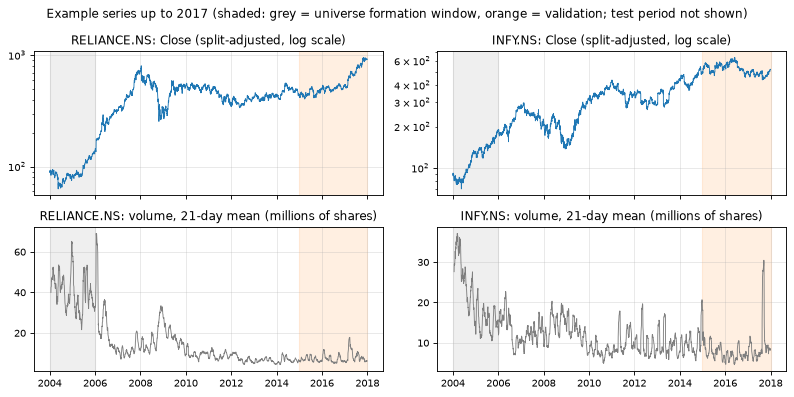

stocks with a close per calendar date (2006-2017): min 138, median 149, max 150


In [7]:
def save_fig(fig, name):
    fig.savefig(ARTIFACTS / name, dpi=100, bbox_inches="tight")
    plt.show()


EDA_END = pd.Timestamp(TEST_START) - pd.Timedelta(days=1)    # the test period is not looked at here
eda = {k: v.loc[:EDA_END] for k, v in P.items()}
fig, axes = plt.subplots(2, 2, figsize=(10, 5), sharex=True)
for j, t in enumerate(["RELIANCE.NS", "INFY.NS"]):
    axes[0, j].semilogy(eda["Close"].index, eda["Close"][t], lw=0.8)
    axes[0, j].set_title(f"{t}: Close (split-adjusted, log scale)")
    axes[1, j].plot(eda["Volume"].index, eda["Volume"][t].rolling(21, min_periods=15).mean() / 1e6, lw=0.8, color="tab:gray")
    axes[1, j].set_title(f"{t}: volume, 21-day mean (millions of shares)")
for ax in axes.ravel():
    ax.axvspan(pd.Timestamp(FORMATION_START), pd.Timestamp(FORMATION_END), color="tab:gray", alpha=0.12)
    ax.axvspan(pd.Timestamp(VAL_START), EDA_END, color="tab:orange", alpha=0.12)
fig.suptitle("Example series up to 2017 (shaded: grey = universe formation window, orange = validation; test period not shown)")
fig.tight_layout()
save_fig(fig, "fig_price_volume.png")

n_stocks = eda["Close"].loc[SAMPLE_START:].notna().sum(axis=1)
print(f"stocks with a close per calendar date (2006-2017): min {n_stocks.min()}, median {int(n_stocks.median())}, max {n_stocks.max()}")

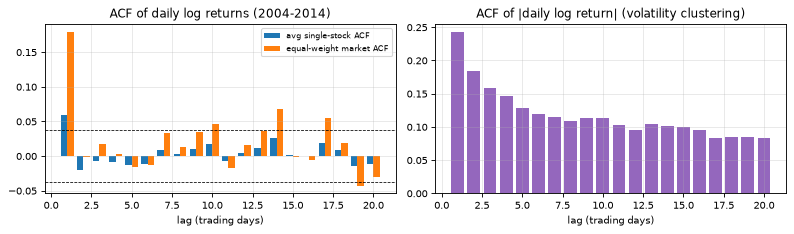

                 1       2       3       4       5       6       7       8       9       10
acf_ret      0.0587 -0.0202 -0.0068 -0.0085 -0.0135 -0.0115  0.0086  0.0033  0.0110  0.0173
acf_mkt      0.1792 -0.0012  0.0179  0.0028 -0.0153 -0.0133  0.0329  0.0134  0.0346  0.0464
acf_abs_ret  0.2424  0.1839  0.1584  0.1466  0.1288  0.1195  0.1147  0.1085  0.1135  0.1130
approx. 95% band for a single stock's ACF: +/-0.0377
daily log return (pre-2015): mean 0.00050, std 0.0292
calendar dates by weekday (0=Mon): {0: 810, 1: 812, 2: 812, 3: 807, 4: 799}


In [8]:
# Autocorrelation of daily log returns, pre-validation period only.
lr_dev = R["lr"].loc[:pd.Timestamp(VAL_START) - pd.Timedelta(days=1)]
LAGS = range(1, 21)


def mean_acf(frame, lags):
    return pd.Series({k: frame.apply(lambda s: s.autocorr(k)).mean() for k in lags})


acf_ret = mean_acf(lr_dev, LAGS)
acf_abs = mean_acf(lr_dev.abs(), LAGS)
mkt = lr_dev.mean(axis=1)
acf_mkt = pd.Series({k: mkt.autocorr(k) for k in LAGS})
conf = 1.96 / np.sqrt(lr_dev.notna().sum().median())

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].bar(np.array(LAGS) - 0.2, acf_ret, width=0.4, label="avg single-stock ACF")
ax[0].bar(np.array(LAGS) + 0.2, acf_mkt, width=0.4, label="equal-weight market ACF")
ax[0].axhline(conf, ls="--", c="k", lw=0.7); ax[0].axhline(-conf, ls="--", c="k", lw=0.7)
ax[0].set_title("ACF of daily log returns (2004-2014)"); ax[0].set_xlabel("lag (trading days)"); ax[0].legend(fontsize=7)
ax[1].bar(LAGS, acf_abs, color="tab:purple")
ax[1].set_title("ACF of |daily log return| (volatility clustering)"); ax[1].set_xlabel("lag (trading days)")
fig.tight_layout()
save_fig(fig, "fig_acf.png")
print(pd.DataFrame({"acf_ret": acf_ret, "acf_mkt": acf_mkt, "acf_abs_ret": acf_abs}).head(10).round(4).T.to_string())
print(f"approx. 95% band for a single stock's ACF: +/-{conf:.4f}")
print(f"daily log return (pre-2015): mean {np.nanmean(lr_dev.values):.5f}, std {np.nanstd(lr_dev.values):.4f}")
wd = pd.Series(calendar.dayofweek).value_counts().sort_index()
print("calendar dates by weekday (0=Mon):", wd.to_dict())

**Horizon choice, h = 5 trading days.** The data are daily with a five-day trading week (weekday counts
above; a handful of special Saturday sessions). Daily return autocorrelation is small and concentrated in
the first lags (single stocks show a mildly positive lag-1 term, the equal-weight market a larger one),
while absolute returns stay autocorrelated for weeks (volatility clustering). A one-day target would be
dominated by microstructure noise and those lag-1 effects; a one-week horizon still sits within the range
where short-term reversal/momentum effects are documented, and the 2006-2014 training period still contains
about 450 non-overlapping 5-day periods. h is fixed here and never tuned on validation or test results.

## 7. Feature engineering and feature audit

All features for row *t* are computed from rows `<= t` of the same stock (trailing windows only, no
centred windows), plus two same-date cross-sectional averages. Price-level features are scale-free ratios,
computed on the break-neutralised price index from Section 5.

**Cross-sectional features:** `mkt_ret_1` and `mkt_ret_5` are the equal-weighted universe averages of
`ret_1` / `ret_5` on the same date *t*. The universe is fixed ex ante, and the average uses only date-*t*
values. They let models separate market-wide moves from stock-specific ones. No other
cross-sectional normalisation is applied; standardisation happens inside model pipelines, fitted on
training data only.

**Target:** `target = Close(t+h)/Close(t) - 1`, dropped when `Close(t+h)` is missing or when a data break
occurs in `(t, t+h]`. The last h rows of every stock have no label and are dropped.

In [9]:
def build_features(P):
    """Wide OHLCV panels (calendar x ticker) -> long feature frame indexed by (Date, ticker)."""
    O, H, L, C, V = (P[k] for k in ["Open", "High", "Low", "Close", "Volume"])
    R_ = clean_returns(C)
    lr, ci = R_["lr"], R_["ci"]
    ci_ff = ci.ffill(limit=MAX_FFILL)
    r1 = np.expm1(lr)
    mp = lambda n: int(np.ceil(0.8 * n))   # min_periods: tolerate a few missing days in a window
    f = {"ret_1": r1}
    for k in range(1, 5):
        f[f"ret_1_lag{k}"] = r1.shift(k)
    for n in (5, 10, 21, 63, 126):
        f[f"ret_{n}"] = ci_ff / ci_ff.shift(n) - 1
    f["mean_ret_21"] = lr.rolling(21, min_periods=mp(21)).mean()
    for n in (5, 21, 63):
        f[f"vol_{n}"] = lr.rolling(n, min_periods=mp(n)).std()
    f["vol_ratio_5_63"] = f["vol_5"] / f["vol_63"]
    sma = {n: ci.rolling(n, min_periods=mp(n)).mean() for n in (5, 21, 63)}
    for n in (5, 21, 63):
        f[f"close_sma_{n}"] = ci / sma[n] - 1
    f["sma5_sma21"] = sma[5] / sma[21] - 1
    hi = np.fmax(np.fmax(H, O), C)
    lo = np.fmin(np.fmin(L, O), C)
    f["hl_range"] = (hi - lo) / C
    f["hl_range_21"] = f["hl_range"].rolling(21, min_periods=mp(21)).mean()
    f["oc_ret"] = C / O - 1
    f["gap_ret"] = (O / C.ffill(limit=MAX_FFILL).shift(1) - 1).mask(R_["brk"])
    f["close_loc"] = ((C - lo) / (hi - lo)).where(hi > lo, 0.5).where(C.notna())
    logv = np.log(V)
    f["volume_chg"] = logv - logv.shift(1)
    f["volume_ratio_21"] = np.log(V / V.rolling(21, min_periods=mp(21)).mean())
    gain = r1.clip(lower=0).rolling(14, min_periods=mp(14)).mean()
    loss = (-r1).clip(lower=0).rolling(14, min_periods=mp(14)).mean()
    f["rsi_14"] = (100 * gain / (gain + loss)).where((gain + loss) > 0, 50.0).where(gain.notna())
    f["mkt_ret_1"] = pd.DataFrame({t: r1.mean(axis=1) for t in C.columns})
    f["mkt_ret_5"] = pd.DataFrame({t: f["ret_5"].mean(axis=1) for t in C.columns})
    out = pd.concat({k: v.where(C.notna()).stack() for k, v in f.items()}, axis=1)
    out.index.names = ["Date", "ticker"]
    return out


def build_target(P, h):
    C = P["Close"]
    brk = clean_returns(C)["brk"].astype(float)
    brk_ahead = brk.rolling(h, min_periods=1).max().shift(-h)      # any break in (t, t+h]
    y = (C.shift(-h) / C - 1).mask(brk_ahead > 0)
    return y.stack().rename("target")


t0 = time.time()
FEATS = build_features(P)
FEATURES = list(FEATS.columns)
TARGET = build_target(P, HORIZON)
print(f"{len(FEATURES)} features built in {time.time() - t0:.1f}s; long frame {FEATS.shape}")

29 features built in 1.6s; long frame (606000, 29)


In [10]:
# Feature audit: formula, lookback, latest timestamp used. Verified programmatically below.
AUDIT_SPEC = {
    "ret_1": ("C_t / C_{t-1} - 1 (break-neutralised)", 1),
    **{f"ret_1_lag{k}": (f"ret_1 at t-{k}", k + 1) for k in range(1, 5)},
    **{f"ret_{n}": (f"CI_t / CI_(t-{n}) - 1 (momentum / trailing return)", n) for n in (5, 10, 21, 63, 126)},
    "mean_ret_21": ("mean of daily log returns over t-20..t", 21),
    **{f"vol_{n}": (f"std of daily log returns over t-{n - 1}..t", n) for n in (5, 21, 63)},
    "vol_ratio_5_63": ("vol_5 / vol_63", 63),
    **{f"close_sma_{n}": (f"CI_t / SMA_{n}(CI)_t - 1 (trailing SMA)", n) for n in (5, 21, 63)},
    "sma5_sma21": ("SMA_5(CI)_t / SMA_21(CI)_t - 1", 21),
    "hl_range": ("(max(O,H,C)_t - min(O,L,C)_t) / C_t", 0),
    "hl_range_21": ("mean of hl_range over t-20..t", 21),
    "oc_ret": ("C_t / O_t - 1 (intraday return)", 0),
    "gap_ret": ("O_t / C_{t-1} - 1 (overnight gap)", 1),
    "close_loc": ("(C_t - min) / (max - min) of day t's range", 0),
    "volume_chg": ("ln V_t - ln V_{t-1}", 1),
    "volume_ratio_21": ("ln(V_t / mean(V_{t-20..t}))", 21),
    "rsi_14": ("100 * avg gain / (avg gain + avg loss), simple 14-day means", 14),
    "mkt_ret_1": ("cross-sectional mean of ret_1 on date t (same-date only)", 1),
    "mkt_ret_5": ("cross-sectional mean of ret_5 on date t (same-date only)", 5),
}
assert set(AUDIT_SPEC) == set(FEATURES)


def leakage_check(P, cutoffs, seed):
    """For each cutoff T: (a) recompute features on data truncated at T; (b) recompute after replacing every
    row after T with random noise. Features for all dates <= T must be identical to the full-data features."""
    rng = np.random.default_rng(seed)
    worst = pd.DataFrame(0.0, index=FEATURES, columns=["max_abs_diff_truncated", "max_abs_diff_future_noise"])
    for T in pd.to_datetime(cutoffs):
        ref = FEATS.loc[:T]
        trunc = build_features({k: v.loc[:T] for k, v in P.items()}).loc[:T]
        noisy = {k: v.copy() for k, v in P.items()}
        for k in noisy:
            after = noisy[k].index > T
            noisy[k].loc[after] = noisy[k].loc[after].values * rng.uniform(0.5, 2.0, noisy[k].loc[after].shape)
        pert = build_features(noisy).loc[:T]
        for col, other in [("max_abs_diff_truncated", trunc), ("max_abs_diff_future_noise", pert)]:
            a, b = ref.to_numpy(), other.reindex(ref.index).to_numpy()
            assert np.array_equal(np.isnan(a), np.isnan(b)), f"NaN pattern changed at cutoff {T.date()}"
            d = np.nanmax(np.abs(a - b), axis=0)
            worst[col] = np.maximum(worst[col], d)
    return worst


t0 = time.time()
LEAK_CUTOFFS = ["2010-06-30", "2014-12-31", "2017-12-29"]
leak = leakage_check(P, LEAK_CUTOFFS, SEED)
audit = pd.DataFrame([(k, *AUDIT_SPEC[k]) for k in FEATURES], columns=["feature", "formula", "lookback_days"])
audit["latest_timestamp_used"] = "t"
audit["uses_future_data"] = ~((leak.max_abs_diff_truncated.values == 0) & (leak.max_abs_diff_future_noise.values == 0))
audit = audit.join(leak, on="feature")
target_row = pd.DataFrame([{"feature": "target (label only)", "formula": f"Close_(t+{HORIZON}) / Close_t - 1",
                            "lookback_days": None, "latest_timestamp_used": f"t+{HORIZON}",
                            "uses_future_data": True}])
pd.concat([audit, target_row], ignore_index=True).to_csv(ARTIFACTS / "feature_audit.csv", index=False)
print(f"leakage check at cutoffs {LEAK_CUTOFFS} took {time.time() - t0:.1f}s")
print(f"features changed by truncating / perturbing the future: {int(audit.uses_future_data.sum())} of {len(audit)}")
assert not audit.uses_future_data.any(), "look-ahead leakage detected"
audit[["feature", "formula", "lookback_days", "latest_timestamp_used", "uses_future_data"]]

leakage check at cutoffs ['2010-06-30', '2014-12-31', '2017-12-29'] took 8.5s
features changed by truncating / perturbing the future: 0 of 29


,feature,formula,lookback_days,latest_timestamp_used,uses_future_data
0,ret_1,C_t / C_{t-1} - 1 (break-neutralised),1,t,False
1,ret_1_lag1,ret_1 at t-1,2,t,False
2,ret_1_lag2,ret_1 at t-2,3,t,False
3,ret_1_lag3,ret_1 at t-3,4,t,False
4,ret_1_lag4,ret_1 at t-4,5,t,False
5,ret_5,CI_t / CI_(t-5) - 1 (momentum / trailing return),5,t,False
6,ret_10,CI_t / CI_(t-10) - 1 (momentum / trailing return),10,t,False
7,ret_21,CI_t / CI_(t-21) - 1 (momentum / trailing return),21,t,False
8,ret_63,CI_t / CI_(t-63) - 1 (momentum / trailing return),63,t,False
9,ret_126,CI_t / CI_(t-126) - 1 (momentum / trailing ret...,126,t,False


## 8. Train / validation / test split

A single global chronological split by date:

| block | prediction dates |
|---|---|
| train | 2006-01-01 .. 2014-12-31 |
| validation | 2015-01-01 .. 2017-12-31 |
| test | 2018-01-01 .. 2020-06-05 (untouched until Section 12) |

**Purge / embargo:** a sample at *t* has a label that ends at *t+h*. The last *h* trading days of every
block that precedes another block are removed, so no training label overlaps the next block's dates (this
h-day gap is the embargo). The same rule applies to every walk-forward fold. Imputers and scalers live inside
model pipelines and are therefore fitted on the training rows of each fold only.

In [11]:
DATA = FEATS.join(TARGET, how="inner")
DATA = DATA[DATA.index.get_level_values("Date") >= SAMPLE_START]
n_candidates = len(DATA)
DATA = DATA.dropna()
assert not DATA.index.duplicated().any()
CAL_POS = pd.Series(np.arange(len(calendar)), index=calendar)
DATES = DATA.index.get_level_values("Date")
DPOS = CAL_POS.reindex(DATES).to_numpy()


def block(start, end, purge=True):
    """Boolean mask for samples with start <= date < end; with purge, also drop the last HORIZON calendar
    dates before `end` so that every label (t .. t+h) ends strictly before `end`."""
    m = (DATES >= pd.Timestamp(start)) & (DATES < pd.Timestamp(end))
    if purge:
        end_pos = CAL_POS.index.searchsorted(pd.Timestamp(end))
        m &= DPOS < end_pos - HORIZON
    return m


END = calendar.max() + pd.Timedelta(days=1)
M_TRAIN = block(SAMPLE_START, VAL_START)
M_VAL = block(VAL_START, TEST_START)
M_TEST = block(TEST_START, END, purge=False)
M_DEV = block(SAMPLE_START, TEST_START)        # train + validation, used for the final refit


def label_end(mask):
    return calendar[DPOS[mask].max() + HORIZON]


split_tbl = pd.DataFrame({
    name: {"rows": int(m.sum()), "stocks": DATA[m].index.get_level_values("ticker").nunique(),
           "first_date": DATES[m].min().date(), "last_date": DATES[m].max().date(),
           "last_label_end": label_end(m).date()}
    for name, m in [("train", M_TRAIN), ("validation", M_VAL), ("test", M_TEST)]}).T
split_tbl.to_csv(ARTIFACTS / "splits.csv")
assert label_end(M_TRAIN) < DATES[M_VAL].min() and label_end(M_VAL) < DATES[M_TEST].min()
assert not (M_TRAIN & M_VAL).any() and not (M_VAL & M_TEST).any()
print(f"candidate rows (date >= {SAMPLE_START}): {n_candidates}; rows with complete features and label: {len(DATA)} "
      f"(dropped {n_candidates - len(DATA)}: warm-up, missing days, breaks, last h rows)")
print("embargo check passed: every train label ends before the first validation date, every validation label before the first test date")
split_tbl

candidate rows (date >= 2006-01-01): 531000; rows with complete features and label: 524816 (dropped 6184: warm-up, missing days, breaks, last h rows)
embargo check passed: every train label ends before the first validation date, every validation label before the first test date


,rows,stocks,first_date,last_date,last_label_end
train,326732,150,2006-01-02,2014-12-23,2014-12-31
validation,108687,150,2015-01-01,2017-12-21,2017-12-29
test,87912,150,2018-01-01,2020-05-29,2020-06-05


## 9. Baselines and metrics

* **zero**: predicts a 0% return.
* **persistence** (naive): predicts the trailing h-day return `ret_5` (the last observed 5-day return persists).
* **hist_mean**: predicts the mean training-fold target.

Metrics: MAE, RMSE, R² (`sklearn.r2_score`, relative to the evaluation-period mean; one metric among
several), directional accuracy (share of rows with a non-zero target whose sign is predicted correctly;
undefined for the all-zero forecast), Pearson and Spearman correlation of prediction vs. actual (pooled), and
the **information coefficient (IC)**: the Spearman correlation across stocks computed per date, then averaged.
`IC_tstat_no` uses every h-th date only (non-overlapping labels), because consecutive daily ICs share 4 of 5
label days and are strongly autocorrelated.

In [12]:
BASELINES = ["zero", "persistence", "hist_mean"]
METRICS = ["MAE", "RMSE", "R2", "DirAcc", "Pearson", "Spearman", "IC_mean", "IC_std", "IC_tstat_no"]


def ic_by_date(dates, y, p):
    """Per-date Spearman correlation between predictions and outcomes across stocks."""
    df = pd.DataFrame({"d": np.asarray(dates), "y": np.asarray(y), "p": np.asarray(p, dtype=float)})
    if np.ptp(df.p.to_numpy()) == 0:
        return pd.Series(dtype=float)
    rk = df.groupby("d")[["y", "p"]].rank()
    g = rk.groupby(df.d)
    yc, pc = rk.y - g.y.transform("mean"), rk.p - g.p.transform("mean")
    num = (yc * pc).groupby(df.d).sum()
    den = np.sqrt((yc ** 2).groupby(df.d).sum() * (pc ** 2).groupby(df.d).sum())
    return (num / den).replace([np.inf, -np.inf], np.nan).dropna()


def evaluate(y, p, dates):
    y, p = np.asarray(y), np.asarray(p, dtype=float)
    const = np.ptp(p) == 0
    nz = y != 0
    ic = ic_by_date(dates, y, p)
    ic_no = ic.iloc[::HORIZON]
    return {
        "n": len(y),
        "MAE": mean_absolute_error(y, p),
        "RMSE": float(np.sqrt(mean_squared_error(y, p))),
        "R2": r2_score(y, p),
        "DirAcc": np.nan if np.all(p == 0) else float(np.mean(np.sign(p[nz]) == np.sign(y[nz]))),
        "Pearson": np.nan if const else pearsonr(y, p)[0],
        "Spearman": np.nan if const else spearmanr(y, p)[0],
        "IC_mean": ic.mean() if len(ic) else np.nan,
        "IC_std": ic.std() if len(ic) else np.nan,
        "IC_tstat_no": ic_no.mean() / ic_no.std() * np.sqrt(len(ic_no)) if len(ic) else np.nan,
    }


def baseline_predict(name, y_train, X_eval):
    if name == "zero":
        return np.zeros(len(X_eval))
    if name == "persistence":
        return X_eval["ret_5"].to_numpy()
    if name == "hist_mean":
        return np.full(len(X_eval), float(np.mean(y_train)))
    raise ValueError(name)


X_ALL, Y_ALL = DATA[FEATURES], DATA["target"].to_numpy()
val_rows = []
for b in BASELINES:
    p = baseline_predict(b, Y_ALL[M_TRAIN], X_ALL[M_VAL])
    val_rows.append({"model": b, **evaluate(Y_ALL[M_VAL], p, DATES[M_VAL])})
pd.DataFrame(val_rows).set_index("model").round(5)

,n,MAE,RMSE,R2,DirAcc,Pearson,Spearman,IC_mean,IC_std,IC_tstat_no
model,,,,,,,,,,
zero,108687,0.03861,0.05552,-0.00564,NaN,NaN,NaN,NaN,NaN,NaN
persistence,108687,0.05656,0.07867,-1.01949,0.4845,-0.01472,-0.03293,-0.03266,0.14165,-2.65203
hist_mean,108687,0.03865,0.05536,-0.00001,0.5158,NaN,NaN,NaN,NaN,NaN


## 10. Model training

Hyperparameters are fixed up front (modest sizes for runtime, not tuned on validation or test):

* **LinearRegression**, **Ridge** (alpha = 1000 on standardised features), **ElasticNet** (alpha = 1e-4, l1_ratio = 0.5): median imputer + `StandardScaler` + model.
* **RandomForest**: 100 trees, max_depth 8, min_samples_leaf 200, max_features 0.33, max_samples 0.25.
* **HistGradientBoosting**: 200 iterations, learning rate 0.05, 31 leaves, min_samples_leaf 500, L2 = 1, no early stopping (avoids an internal random split).

LightGBM / XGBoost are **not** included: HistGradientBoosting already is a histogram GBDT of the same
family, so another GBDT would mainly add forking paths. All estimators run on CPU and are deterministic
given `SEED`. Training labels are winsorised at the 0.5% / 99.5% quantiles of the **training fold** to limit
the influence of extreme weeks; evaluation always uses the raw labels.

Evaluation protocol: (1) **expanding-window walk-forward** over the development period with one test year per
fold (2012..2017; each fold trains on 2006..year-1, purged by h days); (2) the fixed **train -> validation** split.

In [13]:
def make_models():
    lin = lambda est: Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler()), ("model", est)])
    return {
        "LinearRegression": lin(LinearRegression()),
        "Ridge": lin(Ridge(alpha=1000.0, random_state=SEED)),
        "ElasticNet": lin(ElasticNet(alpha=1e-4, l1_ratio=0.5, max_iter=5000, random_state=SEED)),
        "RandomForest": Pipeline([("impute", SimpleImputer(strategy="median")),
                                  ("model", RandomForestRegressor(n_estimators=100, max_depth=8, min_samples_leaf=200,
                                                                  max_features=0.33, max_samples=0.25,
                                                                  n_jobs=N_JOBS, random_state=SEED))]),
        "HistGradientBoosting": HistGradientBoostingRegressor(learning_rate=0.05, max_iter=200, max_leaf_nodes=31,
                                                              min_samples_leaf=500, l2_regularization=1.0,
                                                              early_stopping=False, random_state=SEED),
    }


MODEL_NAMES = list(make_models())


def fit_model(name, X_tr, y_tr):
    lo, hi = np.quantile(y_tr, TARGET_CLIP_Q)
    model = make_models()[name]
    model.fit(X_tr, np.clip(y_tr, lo, hi))
    return model


def run_block(m_train, m_eval, label):
    """Fit every baseline and model on m_train, evaluate on m_eval. Returns metrics rows and predictions."""
    X_tr, y_tr = X_ALL[m_train], Y_ALL[m_train]
    X_ev, y_ev, d_ev = X_ALL[m_eval], Y_ALL[m_eval], DATES[m_eval]
    rows, preds, fitted = [], {}, {}
    for b in BASELINES:
        preds[b] = baseline_predict(b, y_tr, X_ev)
        rows.append({"block": label, "model": b, "fit_s": 0.0, **evaluate(y_ev, preds[b], d_ev)})
    for name in MODEL_NAMES:
        t0 = time.time()
        fitted[name] = fit_model(name, X_tr, y_tr)
        preds[name] = fitted[name].predict(X_ev)
        rows.append({"block": label, "model": name, "fit_s": round(time.time() - t0, 1), **evaluate(y_ev, preds[name], d_ev)})
    return rows, preds, fitted


t0 = time.time()
val_rows, VAL_PRED, VAL_MODELS = run_block(M_TRAIN, M_VAL, "validation")
VAL = pd.DataFrame(val_rows).drop(columns="block").set_index("model")
VAL.round(5).to_csv(ARTIFACTS / "validation_metrics.csv")
print(f"train -> validation: {time.time() - t0:.0f}s")
VAL[["n", "MAE", "RMSE", "R2", "DirAcc", "Spearman", "IC_mean", "IC_tstat_no", "fit_s"]].round(5)

train -> validation: 11s


,n,MAE,RMSE,R2,DirAcc,Spearman,IC_mean,IC_tstat_no,fit_s
model,,,,,,,,,
zero,108687,0.03861,0.05552,-0.00564,NaN,NaN,NaN,NaN,0.0
persistence,108687,0.05656,0.07867,-1.01949,0.48450,-0.03293,-0.03266,-2.65203,0.0
hist_mean,108687,0.03865,0.05536,-0.00001,0.51580,NaN,NaN,NaN,0.0
LinearRegression,108687,0.03891,0.05562,-0.00926,0.50347,-0.00761,0.00707,1.24683,1.0
Ridge,108687,0.03891,0.05562,-0.00937,0.50355,-0.00865,0.00634,1.27985,0.8
ElasticNet,108687,0.03889,0.05560,-0.00883,0.50342,-0.01150,0.00468,1.08740,4.1
RandomForest,108687,0.03876,0.05544,-0.00304,0.49933,0.00269,0.00986,1.22333,3.3
HistGradientBoosting,108687,0.03913,0.05585,-0.01772,0.50662,0.01511,0.03483,2.57052,1.3


In [14]:
t_wf = time.time()
wf_rows = []
for year in WF_TEST_YEARS:
    m_tr = block(SAMPLE_START, f"{year}-01-01")
    m_te = block(f"{year}-01-01", f"{year + 1}-01-01")
    assert label_end(m_tr) < DATES[m_te].min() and label_end(m_te) < pd.Timestamp(TEST_START)
    rows, _, _ = run_block(m_tr, m_te, year)
    wf_rows += rows
    print(f"fold {year}: train {int(m_tr.sum()):>7} rows (to {DATES[m_tr].max().date()}), "
          f"test {int(m_te.sum()):>6} rows; {time.time() - t_wf:.0f}s elapsed")
WF = pd.DataFrame(wf_rows).rename(columns={"block": "fold"})
WF.round(5).to_csv(ARTIFACTS / "walkforward_folds.csv", index=False)
WF_SECONDS = time.time() - t_wf
print(f"walk-forward over {len(WF_TEST_YEARS)} folds: {WF_SECONDS:.0f}s")
WF.pivot(index="fold", columns="model", values="IC_mean")[BASELINES[1:2] + MODEL_NAMES].round(4)

fold 2012: train  217660 rows (to 2011-12-23), test  35699 rows; 9s elapsed


fold 2013: train  254099 rows (to 2012-12-21), test  36182 rows; 16s elapsed


fold 2014: train  291026 rows (to 2013-12-23), test  34966 rows; 26s elapsed


fold 2015: train  326732 rows (to 2014-12-23), test  35385 rows; 36s elapsed


fold 2016: train  362852 rows (to 2015-12-23), test  35544 rows; 47s elapsed


fold 2017: train  399129 rows (to 2016-12-23), test  36280 rows; 60s elapsed
walk-forward over 6 folds: 60s


model,persistence,LinearRegression,Ridge,ElasticNet,RandomForest,HistGradientBoosting
fold,,,,,,
2012,-0.0194,0.0146,0.0166,0.0127,0.0349,0.0429
2013,-0.0623,0.0299,0.0358,0.0312,0.0458,0.0603
2014,-0.0340,0.0221,0.0246,0.0212,0.0384,0.0555
2015,-0.0403,0.0160,0.0179,0.0158,0.0081,0.0469
2016,-0.0363,0.0156,0.0152,0.0110,0.0211,0.0313
2017,-0.0214,-0.0073,-0.0101,-0.0137,0.0004,0.0235


## 11. Model comparison

Walk-forward mean ± standard deviation across the six yearly folds. The selection rule was fixed in
Section 1 **before** any results were seen:

1. eligible = learned models whose mean per-date IC is positive in at least 2/3 of folds **and** whose mean
   walk-forward RMSE is no more than 1% above the best baseline's (a calibration guard; R² is not used for selection);
2. among eligible models pick the highest mean walk-forward IC;
3. if none is eligible, the final "model" is the persistence baseline and the result is reported as null.

Ranking (IC) matters more than squared error here: 5-day returns are dominated by a common market move that
no stock-level feature predicts, so RMSE/R² are nearly identical across models while cross-sectional
ordering can still differ.

In [15]:
agg = WF.groupby("model", sort=False)[METRICS].agg(["mean", "std"])
pos_folds = WF.groupby("model", sort=False).IC_mean.apply(lambda s: float((s > 0).mean()))
WF_SUMMARY = pd.DataFrame({f"{m}_{s}": agg[(m, s)] for m in METRICS for s in ("mean", "std")})
WF_SUMMARY["IC_positive_folds"] = pos_folds
WF_SUMMARY.round(5).to_csv(ARTIFACTS / "walkforward_summary.csv")

best_baseline_rmse = WF_SUMMARY.loc[BASELINES, "RMSE_mean"].min()
elig = WF_SUMMARY.loc[MODEL_NAMES]
elig = elig[(elig.IC_positive_folds >= MIN_POSITIVE_IC_FOLDS - 1e-9) & (elig.RMSE_mean <= best_baseline_rmse * MAX_RMSE_RATIO)]
FINAL_MODEL = elig.IC_mean_mean.idxmax() if len(elig) else "persistence"

display_cols = ["MAE", "RMSE", "R2", "DirAcc", "Spearman", "IC_mean"]
pretty = pd.DataFrame({c: [f"{WF_SUMMARY.loc[m, c + '_mean']:.5f} ± {WF_SUMMARY.loc[m, c + '_std']:.5f}"
                           for m in WF_SUMMARY.index] for c in display_cols}, index=WF_SUMMARY.index)
pretty["IC>0 folds"] = [f"{int(round(v * len(WF_TEST_YEARS)))}/{len(WF_TEST_YEARS)}" for v in pos_folds]
pretty.to_csv(ARTIFACTS / "walkforward_summary_pretty.csv")
print(f"best baseline walk-forward RMSE: {best_baseline_rmse:.5f}; eligible models: {list(elig.index)}")
print(f"FINAL_MODEL = {FINAL_MODEL}")
pretty

best baseline walk-forward RMSE: 0.05698; eligible models: ['LinearRegression', 'Ridge', 'ElasticNet', 'RandomForest', 'HistGradientBoosting']
FINAL_MODEL = HistGradientBoosting


,MAE,RMSE,R2,DirAcc,Spearman,IC_mean,IC>0 folds
model,,,,,,,
zero,0.04010 ± 0.00348,0.05714 ± 0.00460,-0.01105 ± 0.01200,nan ± nan,nan ± nan,nan ± nan,0/6
persistence,0.05839 ± 0.00533,0.08071 ± 0.00706,-1.01541 ± 0.05698,0.48951 ± 0.00824,-0.02379 ± 0.02793,-0.03561 ± 0.01550,0/6
hist_mean,0.04015 ± 0.00356,0.05698 ± 0.00464,-0.00529 ± 0.00428,0.51257 ± 0.02891,nan ± nan,nan ± nan,0/6
LinearRegression,0.04022 ± 0.00347,0.05701 ± 0.00453,-0.00661 ± 0.00802,0.51407 ± 0.01616,0.03278 ± 0.04651,0.01516 ± 0.01242,5/6
Ridge,0.04022 ± 0.00347,0.05701 ± 0.00453,-0.00645 ± 0.00818,0.51403 ± 0.01584,0.03275 ± 0.04778,0.01666 ± 0.01517,5/6
ElasticNet,0.04021 ± 0.00347,0.05700 ± 0.00453,-0.00622 ± 0.00784,0.51346 ± 0.01647,0.03039 ± 0.04924,0.01303 ± 0.01500,5/6
RandomForest,0.04022 ± 0.00356,0.05698 ± 0.00455,-0.00560 ± 0.00470,0.50392 ± 0.02315,0.01517 ± 0.03712,0.02481 ± 0.01797,6/6
HistGradientBoosting,0.04067 ± 0.00352,0.05744 ± 0.00434,-0.02241 ± 0.01758,0.50544 ± 0.01881,0.01765 ± 0.03084,0.04338 ± 0.01405,6/6


## 12. Final model

The selected model is refitted once on train + validation (2006-01-01 .. 2017-12-31, purged by h days
before the test start) and evaluated on the untouched test period. For context, every baseline and model is
refitted and scored the same way. The test numbers play **no** role in selection.

In [16]:
t0 = time.time()
test_rows, TEST_PRED, TEST_MODELS = run_block(M_DEV, M_TEST, "test")
TEST = pd.DataFrame(test_rows).drop(columns="block").set_index("model")
TEST.round(5).to_csv(ARTIFACTS / "test_metrics.csv")
FINAL_EST = TEST_MODELS.get(FINAL_MODEL)
print(f"refit on {int(M_DEV.sum())} rows (to {DATES[M_DEV].max().date()}); test rows {int(M_TEST.sum())} "
      f"({DATES[M_TEST].min().date()} .. {DATES[M_TEST].max().date()}); {time.time() - t0:.0f}s")
print(f"final model: {FINAL_MODEL}")

refit on 436154 rows (to 2017-12-21); test rows 87912 (2018-01-01 .. 2020-05-29); 12s
final model: HistGradientBoosting


## 13. Evaluation

Test-period metrics for every candidate (the final model is marked). Directional accuracy is compared with
the 50% coin flip, with the naive persistence baseline, and with the "always up" rate (share of positive
targets), which a constant positive forecast such as `hist_mean` attains.

In [17]:
TEST_TABLE = TEST[["n", "MAE", "RMSE", "R2", "DirAcc", "Pearson", "Spearman", "IC_mean", "IC_std", "IC_tstat_no"]].copy()
TEST_TABLE.index = [f"{m} (final)" if m == FINAL_MODEL else m for m in TEST_TABLE.index]
y_te = Y_ALL[M_TEST]
up_rate = float(np.mean(y_te[y_te != 0] > 0))
fm = TEST.loc[FINAL_MODEL]
print(f"test share of positive 5-day returns ('always up' accuracy): {up_rate:.4f}")
print(f"{FINAL_MODEL}: DirAcc {fm.DirAcc:.4f} vs 0.5 chance ({fm.DirAcc - 0.5:+.4f}), "
      f"vs persistence {TEST.loc['persistence', 'DirAcc']:.4f} ({fm.DirAcc - TEST.loc['persistence', 'DirAcc']:+.4f}), "
      f"vs always-up {up_rate:.4f} ({fm.DirAcc - up_rate:+.4f})")
print(f"{FINAL_MODEL}: test IC {fm.IC_mean:.4f} (non-overlapping t-stat {fm.IC_tstat_no:.2f}); "
      f"validation IC {VAL.loc[FINAL_MODEL, 'IC_mean']:.4f}; walk-forward IC {WF_SUMMARY.loc[FINAL_MODEL, 'IC_mean_mean']:.4f} "
      f"± {WF_SUMMARY.loc[FINAL_MODEL, 'IC_mean_std']:.4f}")
TEST_TABLE.round(5)

test share of positive 5-day returns ('always up' accuracy): 0.4498
HistGradientBoosting: DirAcc 0.4821 vs 0.5 chance (-0.0179), vs persistence 0.5091 (-0.0270), vs always-up 0.4498 (+0.0323)
HistGradientBoosting: test IC 0.0484 (non-overlapping t-stat 3.82); validation IC 0.0348; walk-forward IC 0.0434 ± 0.0140


,n,MAE,RMSE,R2,DirAcc,Pearson,Spearman,IC_mean,IC_std,IC_tstat_no
zero,87912,0.04746,0.06967,-0.00308,NaN,NaN,NaN,NaN,NaN,NaN
persistence,87912,0.06525,0.09321,-0.79528,0.50913,0.08259,0.04105,-0.00797,0.15915,-0.15050
hist_mean,87912,0.04801,0.07001,-0.01286,0.44981,NaN,NaN,NaN,NaN,NaN
LinearRegression,87912,0.04782,0.06977,-0.00595,0.48442,0.05696,0.04050,-0.00360,0.15112,-0.96108
Ridge,87912,0.04779,0.06969,-0.00371,0.48501,0.06978,0.04652,-0.00197,0.14857,-0.93754
ElasticNet,87912,0.04778,0.06968,-0.00329,0.48346,0.07271,0.04846,-0.00658,0.14758,-1.22881
RandomForest,87912,0.04790,0.06995,-0.01110,0.46955,0.03948,0.04487,0.03415,0.13868,2.15706
HistGradientBoosting (final),87912,0.04846,0.07052,-0.02763,0.48209,0.03971,0.01685,0.04845,0.14066,3.81596


### Backtest (illustrative, costs included)

Rules, fixed in advance and applied to the **whole** validation and test periods (no sub-period selection):

* signal = model prediction at the close of day *t*; trades execute at the **close of t+1**; positions are held
  for exactly h = 5 trading days to the close of t+1+h; rebalancing every h days gives **non-overlapping** holding periods;
* **long-only**: equal weight in the top 20% of predictions; **long-short**: additionally short the bottom 20% (equal weight);
* cost = 10 bps per side on traded notional; turnover = sum of |weight changes| after weights drift, per rebalance (max 2 per leg);
* the tradable set at *t* is every universe stock with complete features at *t* (labels are not required, so
  the backtest does not filter on future prices); period returns use the break-neutralised close index, and a
  stock without a price at exit (beyond 5 carried days, e.g. merged banks in 2020) contributes 0;
* benchmark: **equal-weight buy-and-hold** of all universe stocks from the first entry date (one-time 10 bps entry cost);
* prices exclude dividends for all legs and the benchmark alike; no borrow cost or short-sale constraint is modelled for the short leg.

In [18]:
CI_EXEC = R["ci"].ffill(limit=MAX_FFILL)


def leg_returns(pred_t, entry, exit_, top):
    order = pred_t.sort_values(ascending=not top)
    k = max(1, int(round(QUANTILE * len(order))))
    names = order.index[:k]
    r = CI_EXEC.loc[exit_, names] / CI_EXEC.loc[entry, names] - 1
    return pd.Series(1.0 / k, index=names), r.fillna(0.0), int(r.isna().sum())


def tradable_predictions(fitted, y_train, start, end):
    """Predictions for every stock with complete features at t (no label needed, so the tradable set
    does not depend on future prices)."""
    F = FEATS.loc[pd.Timestamp(start):pd.Timestamp(end)].dropna()
    if FINAL_MODEL in fitted:
        p = fitted[FINAL_MODEL].predict(F[FEATURES])
    else:
        p = baseline_predict(FINAL_MODEL, y_train, F)
    return pd.Series(p, index=F.index)


def backtest(pr):
    pdates = pr.index.get_level_values("Date").unique()
    rebal = [calendar[i] for i in range(CAL_POS[pdates.min()], CAL_POS[pdates.max()] + 1, HORIZON)]
    w_prev = {"long": pd.Series(dtype=float), "short": pd.Series(dtype=float)}
    rows = []
    for t in rebal:
        i = CAL_POS[t]
        if i + 1 + HORIZON >= len(calendar) or t not in pdates:
            continue
        entry, exit_ = calendar[i + 1], calendar[i + 1 + HORIZON]
        p_t = pr.xs(t, level="Date")
        row = {"signal_date": t, "entry": entry, "exit": exit_, "n_stocks": len(p_t)}
        for leg, top in [("long", True), ("short", False)]:
            w, r, n_miss = leg_returns(p_t, entry, exit_, top)
            row[f"{leg}_missing_exit"] = n_miss
            turnover = float(w.sub(w_prev[leg], fill_value=0.0).abs().sum())
            gross = float((w * r).sum())
            row[f"{leg}_gross"], row[f"{leg}_turnover"] = gross, turnover
            row[f"{leg}_cost"] = turnover * COST_BPS / 1e4
            drift = w * (1 + r)
            w_prev[leg] = drift / drift.sum()
        rows.append(row)
    bt = pd.DataFrame(rows).set_index("entry")
    bt["long_only_net"] = bt.long_gross - bt.long_cost
    bt["long_short_net"] = bt.long_gross - bt.long_cost - bt.short_gross - bt.short_cost
    # equal-weight buy-and-hold benchmark over the same holding periods
    first = bt.index[0]
    held = CI_EXEC.loc[first].dropna().index
    value = (CI_EXEC.loc[:, held].ffill() / CI_EXEC.loc[first, held]).mean(axis=1)
    bt["ew_buy_hold"] = value.loc[bt.exit].to_numpy() / value.loc[bt.index].to_numpy() - 1
    bt.iloc[0, bt.columns.get_loc("ew_buy_hold")] -= COST_BPS / 1e4
    return bt


def perf(r, periods_per_year):
    eq = (1 + r).cumprod()
    return {"periods": len(r), "total_return": eq.iloc[-1] - 1,
            "ann_return": eq.iloc[-1] ** (periods_per_year / len(r)) - 1,
            "ann_vol": r.std() * np.sqrt(periods_per_year),
            "sharpe_rf0": r.mean() / r.std() * np.sqrt(periods_per_year),
            "max_drawdown": (eq / eq.cummax() - 1).min()}


PPY = 252 / HORIZON
bt_tables = {}
BT = {}
bt_inputs = [("validation", tradable_predictions(VAL_MODELS, Y_ALL[M_TRAIN], VAL_START, DATES[M_VAL].max())),
             ("test", tradable_predictions(TEST_MODELS, Y_ALL[M_DEV], TEST_START, calendar.max()))]
for label, pr in bt_inputs:
    bt = backtest(pr)
    BT[label] = bt
    bt["long_short_gross"] = bt.long_gross - bt.short_gross
    cols = ["long_only_net", "long_gross", "long_short_net", "long_short_gross", "ew_buy_hold"]
    t = pd.DataFrame({c: perf(bt[c], PPY) for c in cols}).T.rename(index={"long_gross": "long_only_gross"})
    lt, st_ = bt.long_turnover.mean(), bt.short_turnover.mean()
    t["avg_turnover"] = [lt, lt, lt + st_, lt + st_, np.nan]
    t["avg_cost_per_period"] = [bt.long_cost.mean(), 0.0, (bt.long_cost + bt.short_cost).mean(), 0.0, COST_BPS / 1e4 / len(bt)]
    t.insert(0, "period", label)
    bt_tables[label] = t
BACKTEST = pd.concat(bt_tables.values())
BACKTEST.round(4).to_csv(ARTIFACTS / "backtest_summary.csv")
for label, bt in BT.items():
    yearly = bt.groupby(bt.index.year)[["long_only_net", "long_short_net", "ew_buy_hold"]].apply(lambda d: (1 + d).prod() - 1)
    print(f"{label}: compounded return by calendar year of entry; legs with a missing exit price: "
          f"{int(bt.long_missing_exit.sum() + bt.short_missing_exit.sum())} stock-periods")
    print(yearly.round(4).to_string())
print(f"backtest of {FINAL_MODEL}; test periods: {BT['test'].index.min().date()} .. {BT['test'].exit.max().date()}")
BACKTEST.round(4)

validation: compounded return by calendar year of entry; legs with a missing exit price: 0 stock-periods
       long_only_net  long_short_net  ew_buy_hold
entry                                            
2015          0.0339         -0.0539       0.0697
2016          0.0671         -0.1201       0.1076
2017          0.3556         -0.0300       0.4897
test: compounded return by calendar year of entry; legs with a missing exit price: 0 stock-periods
       long_only_net  long_short_net  ew_buy_hold
entry                                            
2018         -0.1482          0.0654      -0.1763
2019         -0.1415          0.2636      -0.0969
2020         -0.0810          0.1783      -0.1520
backtest of HistGradientBoosting; test periods: 2018-01-02 .. 2020-06-04


,period,periods,total_return,ann_return,ann_vol,sharpe_rf0,max_drawdown,avg_turnover,avg_cost_per_period
long_only_net,validation,147.0,0.4956,0.1480,0.2486,0.6806,-0.3199,1.4435,0.0014
long_only_gross,validation,147.0,0.8478,0.2343,0.2487,0.9726,-0.2727,1.4435,0.0000
long_short_net,validation,147.0,-0.1925,-0.0707,0.1492,-0.4155,-0.2989,2.8707,0.0029
long_short_gross,validation,147.0,0.2319,0.0741,0.1487,0.5561,-0.1444,2.8707,0.0000
ew_buy_hold,validation,147.0,0.7650,0.2151,0.2061,1.0505,-0.2115,NaN,0.0000
long_only_net,test,118.0,-0.3280,-0.1561,0.3556,-0.2989,-0.5897,1.2827,0.0013
long_only_gross,test,118.0,-0.2174,-0.0994,0.3552,-0.1172,-0.5341,1.2827,0.0000
long_short_net,test,118.0,0.5862,0.2178,0.1715,1.2351,-0.1824,2.7038,0.0027
long_short_gross,test,118.0,1.1794,0.3948,0.1709,2.0372,-0.1356,2.7038,0.0000
ew_buy_hold,test,118.0,-0.3692,-0.1787,0.2626,-0.6146,-0.5354,NaN,0.0000


## 14. Visualization

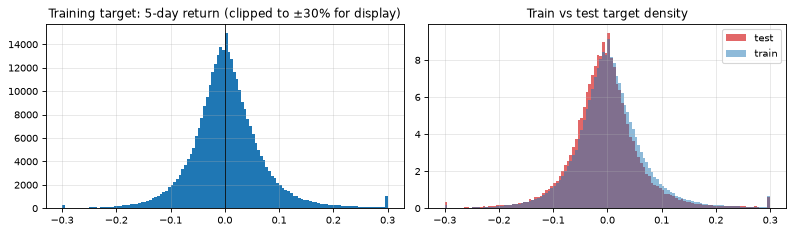

train target: mean 0.00396, std 0.0686, 1%/50%/99% quantiles [-0.1697  0.0009  0.2143]


In [19]:
y_tr = Y_ALL[M_TRAIN]
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].hist(np.clip(y_tr, -0.3, 0.3), bins=120, color="tab:blue")
ax[0].set_title(f"Training target: {HORIZON}-day return (clipped to ±30% for display)")
ax[0].axvline(0, c="k", lw=0.7)
q = np.quantile(y_tr, [0.01, 0.5, 0.99])
ax[1].hist(np.clip(Y_ALL[M_TEST], -0.3, 0.3), bins=120, color="tab:red", alpha=0.7, density=True, label="test")
ax[1].hist(np.clip(y_tr, -0.3, 0.3), bins=120, color="tab:blue", alpha=0.5, density=True, label="train")
ax[1].legend(); ax[1].set_title("Train vs test target density")
fig.tight_layout()
save_fig(fig, "fig_target_distribution.png")
print(f"train target: mean {y_tr.mean():.5f}, std {y_tr.std():.4f}, 1%/50%/99% quantiles {np.round(q, 4)}")

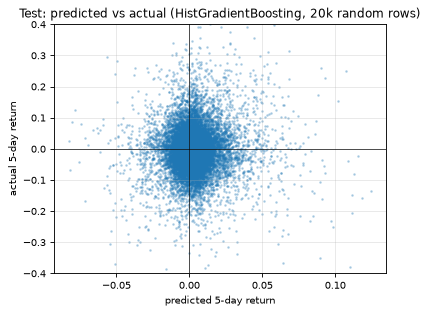

In [20]:
rng = np.random.default_rng(SEED)
idx = rng.choice(int(M_TEST.sum()), size=min(20000, int(M_TEST.sum())), replace=False)
p_fin, y_fin = np.asarray(TEST_PRED[FINAL_MODEL])[idx], y_te[idx]
fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(p_fin, y_fin, s=2, alpha=0.25)
ax.axhline(0, c="k", lw=0.6); ax.axvline(0, c="k", lw=0.6)
ax.set_ylim(-0.4, 0.4)
ax.set_xlabel("predicted 5-day return"); ax.set_ylabel("actual 5-day return")
ax.set_title(f"Test: predicted vs actual ({FINAL_MODEL}, 20k random rows)")
fig.tight_layout()
save_fig(fig, "fig_pred_vs_actual.png")

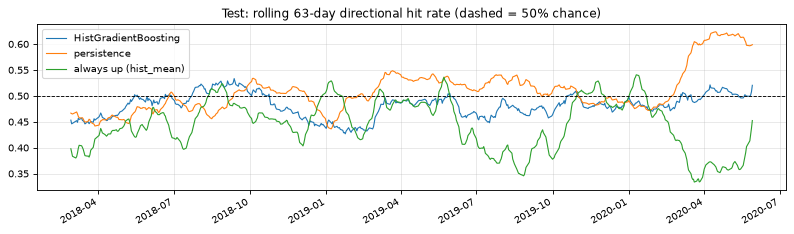

In [21]:
def daily_hit(mask, preds):
    df = pd.DataFrame({"d": DATES[mask], "y": Y_ALL[mask], "p": np.asarray(preds, dtype=float)})
    df = df[df.y != 0]
    return (np.sign(df.p) == np.sign(df.y)).groupby(df.d).mean()


hits = pd.DataFrame({FINAL_MODEL: daily_hit(M_TEST, TEST_PRED[FINAL_MODEL]),
                     "persistence": daily_hit(M_TEST, TEST_PRED["persistence"]),
                     "always up (hist_mean)": daily_hit(M_TEST, TEST_PRED["hist_mean"])})
fig, ax = plt.subplots(figsize=(10, 3))
hits.rolling(63, min_periods=40).mean().plot(ax=ax, lw=1)
ax.axhline(0.5, c="k", ls="--", lw=0.8)
ax.set_title("Test: rolling 63-day directional hit rate (dashed = 50% chance)")
ax.set_xlabel("")
fig.tight_layout()
save_fig(fig, "fig_rolling_hit_rate.png")

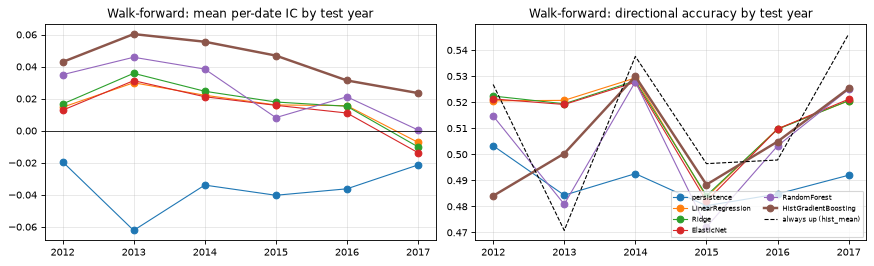

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for m in ["persistence"] + MODEL_NAMES:
    s = WF[WF.model == m].set_index("fold")
    lw = 2.2 if m == FINAL_MODEL else 1
    ax[0].plot(s.index, s.IC_mean, marker="o", lw=lw, label=m)
    ax[1].plot(s.index, s.DirAcc, marker="o", lw=lw, label=m)
s = WF[WF.model == "hist_mean"].set_index("fold")
ax[1].plot(s.index, s.DirAcc, ls="--", c="k", lw=1, label="always up (hist_mean)")
ax[0].axhline(0, c="k", lw=0.7)
ax[0].set_title("Walk-forward: mean per-date IC by test year"); ax[1].set_title("Walk-forward: directional accuracy by test year")
ax[1].legend(fontsize=6, ncol=2, loc="lower right")
fig.tight_layout()
save_fig(fig, "fig_walkforward.png")

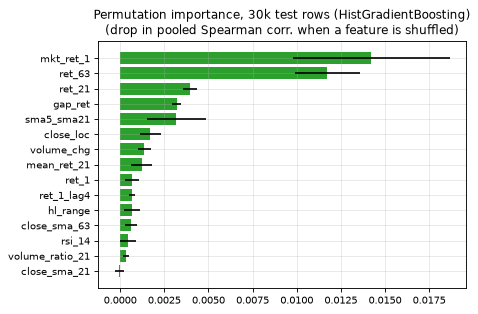

permutation importance: 5s


In [23]:
imp_model_name = FINAL_MODEL if FINAL_EST is not None else "HistGradientBoosting"
imp_est = TEST_MODELS[imp_model_name]
sub = np.flatnonzero(M_TEST)
sub = rng.choice(sub, size=min(30000, len(sub)), replace=False)
spearman_scorer = make_scorer(lambda y, p: spearmanr(y, p)[0])
t0 = time.time()
pi = permutation_importance(imp_est, X_ALL.iloc[sub], Y_ALL[sub], scoring=spearman_scorer,
                            n_repeats=5, random_state=SEED)
IMP = pd.DataFrame({"feature": FEATURES, "importance_mean": pi.importances_mean, "importance_std": pi.importances_std})
IMP = IMP.sort_values("importance_mean", ascending=False)
IMP.round(6).to_csv(ARTIFACTS / "feature_importance.csv", index=False)
top = IMP.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(6, 4))
ax.barh(top.feature, top.importance_mean, xerr=top.importance_std, color="tab:green")
ax.set_title(f"Permutation importance, 30k test rows ({imp_model_name})\n(drop in pooled Spearman corr. when a feature is shuffled)")
fig.tight_layout()
save_fig(fig, "fig_feature_importance.png")
print(f"permutation importance: {time.time() - t0:.0f}s")

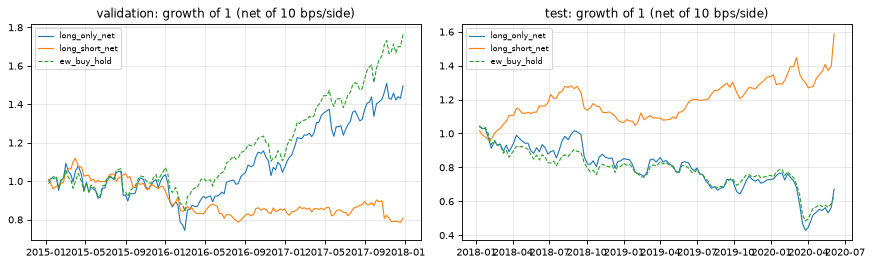

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for j, label in enumerate(["validation", "test"]):
    bt = BT[label]
    for c, st in [("long_only_net", "-"), ("long_short_net", "-"), ("ew_buy_hold", "--")]:
        ax[j].plot(bt.exit, (1 + bt[c]).cumprod(), st, lw=1, label=c)
    ax[j].set_title(f"{label}: growth of 1 (net of {COST_BPS} bps/side)")
    ax[j].legend(fontsize=7)
fig.tight_layout()
save_fig(fig, "fig_backtest.png")

## 15. Diagnostics

Sanity checks that guard against an over-optimistic reading: duplicates / near-duplicate series, target
proxies, a label-shuffle control, stability by year, monotonicity across prediction deciles, and the
leakage check results.

In [25]:
# (a) duplicates and near-duplicate series inside the universe (train period daily returns)
corr = R["lr"].loc[SAMPLE_START:VAL_START].corr(min_periods=500)
iu = np.triu_indices_from(corr, k=1)
pairs = pd.Series(corr.to_numpy()[iu], index=pd.MultiIndex.from_arrays([corr.index[iu[0]], corr.columns[iu[1]]])).dropna()
print(f"duplicate (Date, ticker) rows in modelling frame: {int(DATA.index.duplicated().sum())}")
print("most correlated ticker pairs (daily returns, 2006-2014):")
print(pairs.nlargest(5).round(3).to_string())

# (b) target-proxy check: no single feature should be strongly related to the label
fx = DATA[M_TRAIN].sample(n=100000, random_state=SEED)
proxy = fx[FEATURES].corrwith(fx.target, method="spearman").sort_values(key=np.abs, ascending=False)
print(f"\nlargest |Spearman(feature, target)| on train sample: {proxy.index[0]} = {proxy.iloc[0]:.4f}")
print(proxy.head(5).round(4).to_string())

duplicate (Date, ticker) rows in modelling frame: 0
most correlated ticker pairs (daily returns, 2006-2014):
ticker         ticker      
CHAMBLFERT.NS  NAGAFERT.NS     0.795
BPCL.NS        HINDPETRO.NS    0.774
HINDPETRO.NS   IOC.NS          0.745
ANDHRABANK.NS  SYNDIBANK.NS    0.728
RELCAPITAL.NS  RELINFRA.NS     0.727



largest |Spearman(feature, target)| on train sample: mkt_ret_1 = 0.0442
mkt_ret_1     0.0442
rsi_14        0.0346
sma5_sma21    0.0341
mkt_ret_5     0.0290
gap_ret       0.0288


In [26]:
# (c) label-shuffle control: same pipeline, training labels permuted within the training block
ctrl_name = FINAL_MODEL if FINAL_MODEL in MODEL_NAMES else "Ridge"
y_shuf = np.random.default_rng(SEED).permutation(Y_ALL[M_TRAIN])
ctrl = fit_model(ctrl_name, X_ALL[M_TRAIN], y_shuf)
ctrl_eval = evaluate(Y_ALL[M_VAL], ctrl.predict(X_ALL[M_VAL]), DATES[M_VAL])
print(f"label-shuffle control ({ctrl_name}, train -> validation): IC {ctrl_eval['IC_mean']:.4f}, "
      f"DirAcc {ctrl_eval['DirAcc']:.4f}  vs real labels: IC {VAL.loc[ctrl_name, 'IC_mean']:.4f}, DirAcc {VAL.loc[ctrl_name, 'DirAcc']:.4f}")

# (d) stability on the test period: IC per calendar year
ic_fin = ic_by_date(DATES[M_TEST], y_te, TEST_PRED[FINAL_MODEL])
ic_per = ic_by_date(DATES[M_TEST], y_te, TEST_PRED["persistence"])
by_year = pd.DataFrame({FINAL_MODEL: ic_fin.groupby(ic_fin.index.year).mean(),
                        "persistence": ic_per.groupby(ic_per.index.year).mean(),
                        f"{FINAL_MODEL} share of days IC>0": (ic_fin > 0).groupby(ic_fin.index.year).mean()})
print("\ntest IC by year:")
print(by_year.round(4).to_string())

# reference: the textbook short-term reversal rule (predict -ret_5) is the sign-flipped persistence baseline
rev = pd.DataFrame({"walk-forward IC (mean of folds)": [-WF_SUMMARY.loc["persistence", "IC_mean_mean"], WF_SUMMARY.loc[FINAL_MODEL, "IC_mean_mean"]],
                    "validation IC": [-VAL.loc["persistence", "IC_mean"], VAL.loc[FINAL_MODEL, "IC_mean"]],
                    "test IC": [-TEST.loc["persistence", "IC_mean"], TEST.loc[FINAL_MODEL, "IC_mean"]]},
                   index=["reversal rule (-ret_5)", FINAL_MODEL])
print("\nmodel vs. a simple short-term reversal rule (IC of -ret_5 = minus the persistence IC):")
print(rev.round(4).to_string())

# (e) decile analysis: mean realised return by prediction decile, decile assigned within each date
dd = pd.DataFrame({"d": DATES[M_TEST], "y": y_te, "p": np.asarray(TEST_PRED[FINAL_MODEL])})
dd["decile"] = dd.groupby("d").p.transform(lambda s: pd.qcut(s.rank(method="first"), 10, labels=False)) + 1
dec = dd.groupby("decile").y.agg(["mean", "count"])
dec["mean_minus_all"] = dec["mean"] - dd.y.mean()
DECILES = dec
dec.round(5).to_csv(ARTIFACTS / "test_deciles.csv")
print("\ntest: mean 5-day return by within-date prediction decile (10 = highest predicted):")
print(dec.round(5).T.to_string())

# (f) leakage check results (Section 7) and calibration of the prediction scale
print(f"\nleakage check: max |diff| truncated {leak.max_abs_diff_truncated.max():.1e}, "
      f"future-noise {leak.max_abs_diff_future_noise.max():.1e} over {len(FEATURES)} features")
print(f"prediction std on test {np.std(TEST_PRED[FINAL_MODEL]):.5f} vs target std {np.std(y_te):.5f}")
strong = TEST.loc[MODEL_NAMES, "IC_mean"].abs().max() > 0.10 or TEST.loc[MODEL_NAMES, "R2"].max() > 0.05
print("unusually strong score detected -> investigate" if strong else
      "no unusually strong score (all test |IC| <= 0.10 and R2 <= 0.05)")

label-shuffle control (HistGradientBoosting, train -> validation): IC 0.0073, DirAcc 0.5160  vs real labels: IC 0.0348, DirAcc 0.5066

test IC by year:
      HistGradientBoosting  persistence  HistGradientBoosting share of days IC>0
d                                                                               
2018                0.0478      -0.0438                                   0.5854
2019                0.0387       0.0139                                   0.6074
2020                0.0735       0.0272                                   0.7500

model vs. a simple short-term reversal rule (IC of -ret_5 = minus the persistence IC):
                        walk-forward IC (mean of folds)  validation IC  test IC
reversal rule (-ret_5)                           0.0356         0.0327   0.0080
HistGradientBoosting                             0.0434         0.0348   0.0484



test: mean 5-day return by within-date prediction decile (10 = highest predicted):
decile                  1           2           3           4           5           6           7           8           9           10
mean              -0.01011    -0.00637    -0.00471    -0.00437    -0.00382    -0.00317    -0.00253    -0.00194    -0.00053    -0.00106
count           8820.00000  8771.00000  8819.00000  8771.00000  8819.00000  8732.00000  8770.00000  8820.00000  8770.00000  8820.00000
mean_minus_all    -0.00625    -0.00250    -0.00085    -0.00051     0.00004     0.00069     0.00133     0.00193     0.00333     0.00280

leakage check: max |diff| truncated 0.0e+00, future-noise 0.0e+00 over 29 features
prediction std on test 0.01240 vs target std 0.06956
no unusually strong score (all test |IC| <= 0.10 and R2 <= 0.05)


## 16. Conclusions

In [27]:
RUNTIME_MIN = (time.time() - RUN_START) / 60
fin_wf = WF_SUMMARY.loc[FINAL_MODEL]
lo_te = BACKTEST[(BACKTEST.period == "test")]
print(f"final model: {FINAL_MODEL}")
print(f"walk-forward IC {fin_wf.IC_mean_mean:.4f} ± {fin_wf.IC_mean_std:.4f}; DirAcc {fin_wf.DirAcc_mean:.4f} ± {fin_wf.DirAcc_std:.4f}")
print(f"test: IC {fm.IC_mean:.4f}, DirAcc {fm.DirAcc:.4f}, R2 {fm.R2:.5f}, RMSE {fm.RMSE:.5f} "
      f"(zero baseline RMSE {TEST.loc['zero', 'RMSE']:.5f})")
print(f"test backtest Sharpe (rf=0): long-only {lo_te.loc['long_only_net', 'sharpe_rf0']:.2f}, long-short "
      f"{lo_te.loc['long_short_net', 'sharpe_rf0']:.2f}, EW buy-and-hold {lo_te.loc['ew_buy_hold', 'sharpe_rf0']:.2f}")
run_info = pd.Series({**ENV, "runtime_minutes": round(RUNTIME_MIN, 1), "final_model": FINAL_MODEL,
                      "combined_sha256_nse_files": COMBINED_SHA256, "download_date": download_date})
run_info.to_frame("value").to_csv(ARTIFACTS / "run_info.csv")
print(f"total runtime: {RUNTIME_MIN:.1f} min on {ENV['processor']} ({ENV['logical_cpus']} logical CPUs); GPU used: {USE_GPU}")

final model: HistGradientBoosting
walk-forward IC 0.0434 ± 0.0140; DirAcc 0.5054 ± 0.0188
test: IC 0.0484, DirAcc 0.4821, R2 -0.02763, RMSE 0.07052 (zero baseline RMSE 0.06967)
test backtest Sharpe (rf=0): long-only -0.30, long-short 1.24, EW buy-and-hold -0.61
total runtime: 2.2 min on Intel(R) Core(TM) Ultra 9 275HX (24 logical CPUs); GPU used: False


### What the experiment shows (all figures are in the outputs above)

1. **Point forecasts of the 5-day return are not useful.** No learned model achieves a lower RMSE than the
   best baseline in validation or test, and every learned model has a negative R² in both. As a
   predictor of the *size* of next week's return, the zero or training-mean forecast is as good as anything here.
2. **Direction is not predicted either.** Directional accuracy hovers around the base rate of up-weeks. On
   the test period (2018 to mid-2020, when down-weeks outnumbered up-weeks) the final model's hit rate is below
   50% and below the naive persistence baseline, mostly because it carries the positive drift of the
   training years.
3. **There is a small, stable cross-sectional ranking signal.** HistGradientBoosting has a positive mean
   per-date IC in every walk-forward fold, on validation and on test. The label-shuffle control is near zero,
   the look-ahead checks pass, no feature is a strong proxy for the label, and the size of the IC is in the range
   usually reported for short-horizon equity return prediction, not suspiciously large. In walk-forward and
   validation, the plain short-term reversal rule (`-ret_5`) reaches most of that IC by itself. On the test
   period the reversal rule is weak while the model keeps its IC (see the comparison in Section 15).
4. **The ranking signal is not a robust strategy after costs.** Turnover is high, so 10 bps per side
   matters. The long-short portfolio lost money net of costs in validation and made money in test, and the
   long-only portfolio mostly tracks the equal-weight benchmark. This instability means the backtest cannot be
   read as evidence of a tradable edge.

### Why HistGradientBoosting is the final model

It was chosen by the rule fixed in Section 1 (highest mean walk-forward IC among models with IC > 0 in at
least 2/3 of folds and walk-forward RMSE within 1% of the best baseline), *not* by test results. It has the
**lowest** R² of the learned models, and the choice is deliberate: R² is dominated by the market-wide
component of returns, which none of the features forecasts, while the IC measures the only thing any model
here does better than chance, which is ordering stocks within a date. For a forecast of the return itself,
the honest recommendation is the baseline.

### Caveats

Survivorship bias in the source files, price returns without dividends, a single data vendor of uneven quality,
fixed (untuned) hyperparameters and a single test window that includes the COVID-19 crash. See the README
for the full list. These experiments on historical data are not financial advice.